# 1.CuerpoNegro
### Física Electrónica - UTN FRA
*Cuaderno interactivo adaptado para Google Colab.*

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/)


In [1]:
import matplotlib.pyplot as plt  # Paquete gráfico
import numpy as np

k_B=1.38064852e-23     # Constante de Boltzmann en J/K
v_c=299792458          # Velocidad de la luz en m/s

# Ley de Rayleigh-Jeans (Cantidad de energía emitida por el cuerpo negro por unidad de volumen, a la frecuencia v y la temperatura T)

def p(v,T):
    return (8*np.pi*(v**2)*k_B*T)/(v_c**3)

# Gráfico de la ley de Rayleigh-Jeans a temperatura constante T

def RJ(T):
  v=np.linspace(0,1e14,200)
  fig, ax = plt.subplots()
  ax.plot(v,p(v,T),color='orange',label='{:d}°K'.format(T))
  ax.set_xlim(0,1e14)
  ax.set_ylim(0,3e-17)
  ax.set_xlabel('Frecuencia ($Hz$)')
  ax.set_ylabel('Densidad de energía ($Js/m^3$)')
  ax.set_title('Predicción de Rayleigh-Jeans')
  ax.legend()

# Ley de Planck (Cantidad de energía emitida por el cuerpo negro por unidad de volumen, a la frecuencia v y la temperatura T)

h_p=6.62607004e-34     # Constante de Planck

# Densidad de energía a una longitud de onda v y temperatura T

def pP(v,T):
  return (8*np.pi*h_p*(v**3))/((v_c**3)* ((np.exp((h_p*v)/(k_B*T))) - 1))

# Frecuencia de emision máxima a la temperatura T (Planck): v=2.8214*k_B*T/h=5.878841773196831e10*T

def vmaxP(T):
    M=5.878841773196831e10*T*1e-14
    M1=round(M,4)
    print(M1,'(e14) Hertz')


# Gráfica de la ley de Planck, el rango de temperatura que admite es [1,43000] grados Kelvin

def Planck(T):
  vm=5.878841773196831e10*T
  v=np.linspace(0.1,5*vm,200)
  fig, ax = plt.subplots()
  ax.plot(v,pP(v,T),color='red',label='{:d}°K'.format(T))
  ax.set_title('Espectro predicho por Planck')
  ax.set_xlabel('Frecuencia (Hz)')
  ax.set_ylabel('Densidad de energía (Js/m$^3$)')
  ax.legend()
  print('v(máx):')
  vmaxP(T)

# Superposición de espectros térmicos de un cuerpo negro a cuatro temperaturas dadas (predichos por Planck).

def PRJ(T):
  vm=5.878841773196831e10*T
  v=np.linspace(0.1,5*vm,200)
  v1=np.linspace(0.1,vm,100)
  fig, ax = plt.subplots()
  ax.plot(v,pP(v,T),color='red',label='Experimental')
  ax.plot(v1,p(v1,T),color='orange',label='Rayleigh-Jeans')
  ax.set_title('Rayleigh-Jeans vs experimental a {:d}°K'.format(T))
  ax.set_xlabel('Frecuencia ($Hz$)')
  ax.set_ylabel('Densidad de energía ($Js/m^3$)')
  ax.legend()

# Superposición de espectros térmicos de un cuerpo negro a cuatro temperaturas dadas (predichos por Planck).

def SPlanck(x):
  for t in x:
    vm=5.878841773196831e10*x[len(x)-1]
    v=np.linspace(0.1,5*vm,200)
    plt.plot(v,pP(v,t),label='{:d}°K'.format(t))
    plt.title('Espectros predichos por Planck')
    plt.xlabel('Frecuencia (Hz)')
    plt.ylabel('Densidad de energía ($Js/m^3$)')
    plt.legend()

# Gráfico de temperatura vs vmax para n temperaturas

def max(T):
    return (T*v_c)/(0.0028976)

def maxim(x):
  s=[]
  for t in x:
    s.append(max(t))
  plt.plot(x,s,'o')
  plt.xlabel('Temperatura (°K)')
  plt.ylabel('frecuencia $Hz$')

# **RADIACIÓN TÉRMICA**

Se llama $\textbf{radiación térmica}$ a la radiación emitida por un cuerpo como consecuencia de su temperatura. Si en un principio el cuerpo está más caliente que sus alrededores, este se enfriará ya que la rapidez con que emite energía excederá la rapidez con la que absorbe energía. La materia condensada (sólidos o líquidos) emiten un espectro de radiación continuo que es altamente dependiente de la temperatura. A temperaturas ordinarias la mayoría de los cuerpos son visibles a causa de la luz que reflejan, más no por la luz que emiten, por lo tanto si no se hace incidir luz sobre ellos no es posible verlos. Sin embargo, a muy altas temperaturas los cuerpos son luminosos por si mismos, en un cuarto obscuro se les puede ver brillar, pero aún a temperaturas de varios miles de grados Kelvin más del 90% de la radiación térmica emitida es invisible para nosotros.

La forma detallada del espectro de radiación térmica emitida por un cuerpo caliente depende de la composición del mismo, sin embargo hay una clase de cuerpos que emiten un espectro térmico universal. Estos son los llamados $\textbf{cuerpos negros}$, es decir, cuerpos cuyas superficies absorben toda la radiación que incide sobre ellos sin importar el ángulo de incidencia o la frecuencia de la radiación, dichos cuerpos al no reflejar luz se ven negros. Una buena aproximación de un cuerpo negro es un objeto con una cavidad en su interior, la cual se comunica con el exterior a través de un pequeño agujero en las paredes del objeto. Por ejemplo, podemos pensar en un cubo hueco con un pequeño agujero en una de sus paredes. Esencialmente toda la radiación que incide sobre el agujero será absorbida y por lo tanto el $\textbf{agujero}$ tendrá todas las propiedades de la superficie de un cuerpo negro. Si las paredes de la cavidad se calientan a una temperatura $T$, estas emitirán radiación térmica que llenará la cavidad y una pequeña parte de la radiación térmica emitida pasará por el agujero. Como el agujero tiene las características de la superficie de un cuerpo negro, la radiación que emite ha de tener el espectro de un cuerpo negro. Sin embargo, como el agujero simplemente muestrea la radiación térmica dentro de la cavidad, resulta evidente que la radiación dentro de la cavidad también debe tener el espectro de un cuerpo negro a la temperatura $T$.

Independientemente de los detalles de su composición todos los cuerpos negros a la misma temperatura emiten el mismo espectro de radiación térmica. Cuando la radiación encerrada dentro de la cavidad alcanza el equilibrio con los átomos de las paredes, la cantidad de energía que emiten los átomos por unidad de tiempo es igual a la que absorben. En consecuencia la densidad de energía (cantida de energía por unidad de volumen) del campo electromagnético existente en la cavidad es constante. Así, la densidad de energía $\rho_T(\nu)$, en el intervalo de frecuencias entre $\nu$ y $\nu + d\nu$, del espectro de un cuerpo negro a una temperatura $T$, es igual al producto de la energía promedio de cada onda estacionaria por el número de ondas estacionarias en el intervalo de frecuencias, dividido entre el volumen de la cavidad. Aplicando las teorías clásicas del electromagnetismo y la termodinámica se obtiene la ley de $Rayleigh-Jeans$, formulada a principios del siglo $XX$.

$$\rho_T(\nu)d\nu=\frac{8\pi\nu^2kT}{c^3}d\nu$$

donde $\nu$ es la frecuencia en $Hz$, $c$ es la velocidad de la luz en $m/s$, $T$ es la temperatura en $K$ y $k$ es la constante de Boltzmann en $J/K$.

Para construir los espectros predichos por la ley de Rayleigh-Jeans empleamos la función $RJ(T)$, cuyo argumento es la temperatura $T$ en grados Kelvin. El siguiente gráfico muestra el espectro térmico para un cuerpo negro a una temperatura de 2000°K.

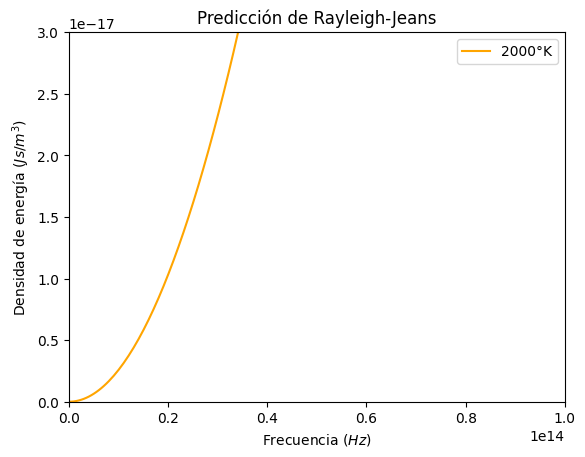

In [2]:
#@title
RJ(2000)

### **Ejercicio 1**

Responda las siguientes preguntas de acuerdo con la Ley de Rayleigh-Jeans:

1. En el gráfico anterior ¿Cómo se comporta la densidad de energía emitidad por el cuerpo negro a medida que aumenta la frecuencia?

2.  En la celda de abajo emplee la función $RJ(T)$, cuyo argumento es la temperatura $T$, para graficar la densidad de energía emitida por un cuerpo negro a la temperatura de 500°K, luego a 1000°K, después a 3000°K y posteriormente a 5000°K, ¿qué puede observar?

## **Espectros  experimentales**

Como pudimos observar en el ejercicio 1, a medida que la frecuencia $\nu$ tiende a infinito, la densidad de energía $\rho_T(\nu)$ también tiende a infinito, lo cual es contradictorio con los experimentos. Experimentalmente la densidad de energía tiende a cero cuando la frecuencia tiende a infinito. El siguiente gráfico utiliza la función $PRJ(T)$, cuyo argumento es la temperatura $T$, para comparar el espectro térmico experimental de un cuerpo negro a 1500ºK con el espectro térmico obtenido a través de la ley de Rayleigh-Jeans.

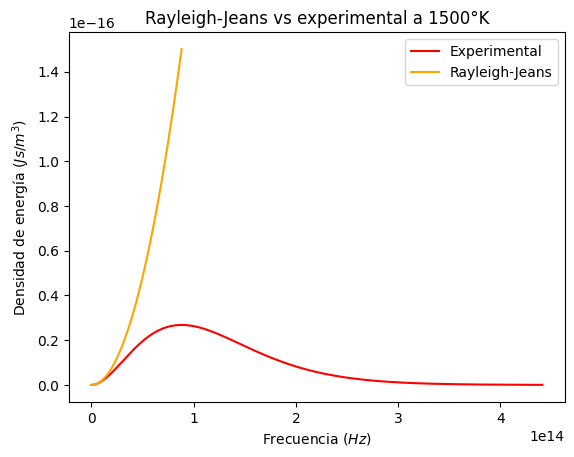

In [4]:

PRJ(1500)

Como vemos la ley de Raleigh-Jeans es coherente con los resultados experimentales a muy bajas frecuencias. Este comportamiento irreal de la predicción clásica teórica se conoce en física como la $\textbf{catastrofe ultraviloeta}$.

## **SOLUCIÓN DADA POR PLANCK**

Al igual que Rayleigh-Jeans, Planck asumio que la radiación emitida por un cuerpo se debia a las oscilaciones de los electrones en las particulas que forman el cuerpo. A diferencia de Rayleigh-Jeans, los cuales asumieron que las energías de las oscilaciones electronicas responsables de la emisión de la radiación podian tomar cualquier valor, Planck asumio que la energía de las oscilaciones era una variable discreta en lugar de una variable continua, es decir, asumio que la energía tenia que ser proporcional a un múltiplo entero de la frecuencia, $E=h\nu$, donde $h$ es la constante que lleva su nombre. A partir de esta suposición junto con argumentos de termodinámica estadística concluyó que

$$\rho_T(\nu)d\nu=\frac{8\pi h \nu^3}{c^3(e^{\frac{h\nu}{kT}}-1)}d\nu$$

En el gráfico de abajo se pueden ver el espectro térmico predichos por Planck, para un cuerpo negro a 1500ºK.

v(máx):
0.8818 (e14) Hertz


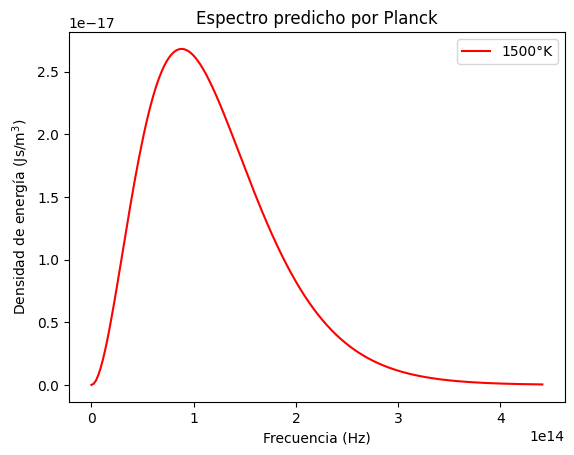

In [5]:
Planck(1500)

### **Ejercicio 2**

1. En la celda de abajo emplee la función $vmaxP(T)$, cuyo argumento es la temperatura $T$ en grados Kelvin, para encontrar la frecuencia de emisión máxima de un cuerpo negro a una temperatura de 1000, 2000, 3000, 4000 y 5000 grados Kelvin. ¿Cuál es la tendencia que presenta este conjunto de datos?

Nota: Si los desea emplee la función $Planck(T)$, cuyo argumento es una temperatura $T$ entre $1$ y $43000$ grados Kelvin, para tener una visión gráfica.

2. De acuerdo con el ítem anterior, ¿qué relación observa entre la frecuencia de emisión máxima y la temperatura?

3. Si $x=[T1,T2,T3,T4,T5]$ es una lista de temperaturas, dada en orden ascendente, utilice la función $SPlanck(x)$ para realizar la gráfica a temperaturas diferentes. ¿Qué puede observar?

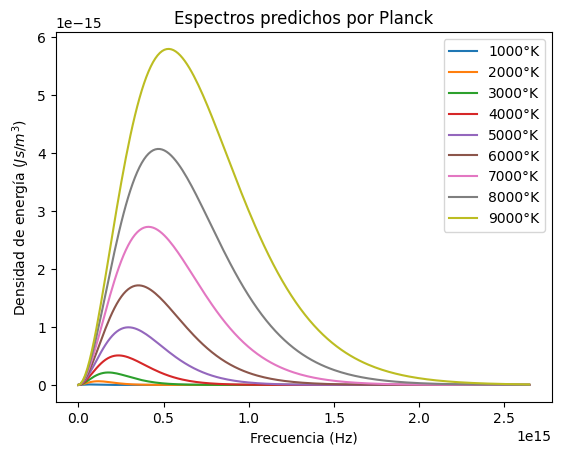

In [6]:
# Ejemplo de uso de la función SPlanck(x):

x=[1000,2000,3000,4000,5000,6000,7000,8000,9000]
SPlanck(x)

### **Ejercicio 3**

La función $maxim(x)$ arroja la gráfica de la frecuencia de emisión máxima a $n$ temperaturas diferentes: $[T1,T2,T3,...,Tn]$, en grados Kelvin. Utilice está función en la celda de abajo para graficar el conjunto de datos del ejercicio anterior. Observe la posición espacial de este conjunto de datos y deduzca una expresión que permita representar tanto la frecuencia como la longitud de onda de emisión máxima en función de la temperatura.

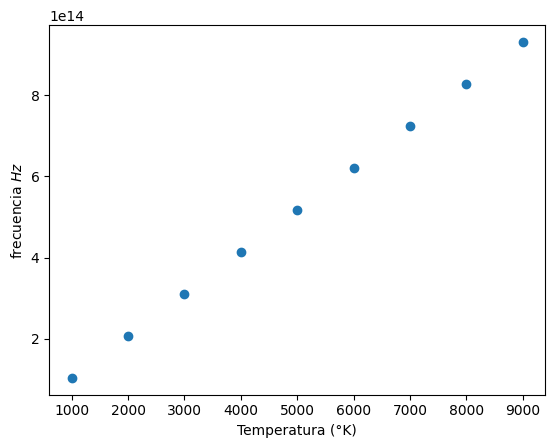

In [7]:
# Ejemplo de uso de la función maxim(x):

x=[1000,2000,3000,4000,5000,6000,7000,8000,9000]
maxim(x)

$\textbf{Nota}$: Como podemos observar la frecuencia de máxima emisión del espectro se desplaza a derecha conforme aumenta la temperatura, es decir, $\nu_{máx}\propto T$. Este resultado que se conoce como la $\mathbf{ley \ de \ desplazamineto \ de \ Wien}$. Experimentalmente se encuentra que $\lambda_{máx}T=2.8978*10^{-3}mK$.

### **Problema 1**

1. Suponga que un filamento de Tungsteno de un foco eléctrico es un cuerpo negro y determine su longitud de onda pico si su temperatura es de $2900 \ K$. ¿Porqué la respuesta a este ejercicio sugiere que más energía de un foco se convierte en calor que en luz?
2. Utilizando la ley de desplazamiento de Wien calcule la temperatura superficial de una estrella gigante roja que radia con una longitud de onda pico de $650 \ nm$.

### **Ejercicios y problemas adicionales**

1. Calcule la energía en electrón volts de un fotón cuya frecuencia es: a) $6.2*10^{14} \ Hz$, b) $3.1 \ GHz$, c) $46 \ MHz$. Determine las longitudes de onda correspondientes a estos fotones.

2. Un radiador de cavidad tiene un agujero de $10 \ mm$ de diámetro. Encuentre la potencia radiada a través del agujero en el intervalo $5500-5510 \ ángstroms$.

# **BIBLIOGRAFÍA**

Eisberg R., Resnick R., Física Cuántica, átomos, móleculas, sólidos, núcleos y partículas, Limusa, 2002.

McQuarrie D., Quantum Chemistry, Viva Books, 2016.

Serway R., Física, vol 2, MacGraw-Hill, 1997.